**Handling Missing Values**

- `Mean | Median | mode `
- `Arbitary Value technique `
- `Constant Value `
- `End of Distribution `
- `Random Sample Imputation `

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/Titanic-Dataset.csv",usecols=['Age'])

df

,Age
0,22.0
1,38.0
2,26.0
3,35.0
4,35.0
...,...
886,27.0
887,19.0
888,NaN
889,26.0


In [6]:
df.isnull().sum()

,0
Age,177


In [10]:
df['Age'].mode()[0]

np.float64(24.0)

In [11]:
df['Age_Mean'] = df['Age'].fillna(df['Age'].mean())
df['Age_Median'] = df['Age'].fillna(df['Age'].median())
df['Age_Mode'] = df['Age'].fillna(df['Age'].mode()[0])

In [12]:
df

,Age,Age_Mean,Age_Median,Age_Mode
0,22.0,22.000000,22.0,22.0
1,38.0,38.000000,38.0,38.0
2,26.0,26.000000,26.0,26.0
3,35.0,35.000000,35.0,35.0
4,35.0,35.000000,35.0,35.0
...,...,...,...,...
886,27.0,27.000000,27.0,27.0
887,19.0,19.000000,19.0,19.0
888,NaN,29.699118,28.0,24.0
889,26.0,26.000000,26.0,26.0


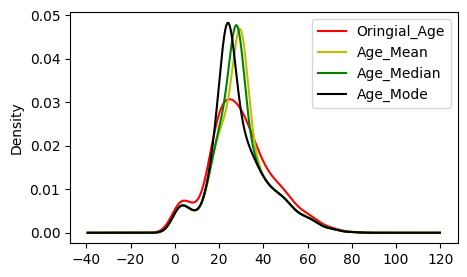

In [13]:
# which one to choose
plt.figure(figsize = (5,3))

df['Age'].plot(kind = 'kde' , color = 'r' , label = 'Oringial_Age')
df['Age_Mean'].plot(kind = 'kde', color = 'y' , label = 'Age_Mean')
df['Age_Median'].plot(kind = 'kde', color = 'g' , label = 'Age_Median')
df['Age_Mode'].plot(kind = 'kde', color = 'black' , label = 'Age_Mode')

plt.legend(loc = 0)

plt.show()

In [14]:
print(f"Original Age column : {df['Age'].std()}")
print(f" Age Mean column : {df['Age_Mean'].std()}")
print(f"Age Median column : {df['Age_Median'].std()}")
print(f"Age Mode column : {df['Age_Mode'].std()}")

Original Age column : 14.526497332334044
 Age Mean column : 13.002015226002884
Age Median column : 13.019696550973194
Age Mode column : 13.199571767746487


In [15]:
# Arbitary value
# constant technique
# End of distribution


df['Age_Arbitary'] = df['Age'].fillna(999)
df['Age_constant'] = np.where(df['Age'].isnull() , 0 , 1)

r = df['Age'].mean() + 3 * df['Age'].std()
df['Age_EOD'] = df['Age'].fillna(r)

In [16]:
df

,Age,Age_Mean,Age_Median,Age_Mode,Age_Arbitary,Age_constant,Age_EOD
0,22.0,22.000000,22.0,22.0,22.0,1,22.00000
1,38.0,38.000000,38.0,38.0,38.0,1,38.00000
2,26.0,26.000000,26.0,26.0,26.0,1,26.00000
3,35.0,35.000000,35.0,35.0,35.0,1,35.00000
4,35.0,35.000000,35.0,35.0,35.0,1,35.00000
...,...,...,...,...,...,...,...
886,27.0,27.000000,27.0,27.0,27.0,1,27.00000
887,19.0,19.000000,19.0,19.0,19.0,1,19.00000
888,NaN,29.699118,28.0,24.0,999.0,0,73.27861
889,26.0,26.000000,26.0,26.0,26.0,1,26.00000


**Random_Sample_Imputation**

In [34]:
t = pd.DataFrame({'Profit' : [110,120,65,np.nan,44,90,np.nan,30,60]})

t

,Profit
0,110.0
1,120.0
2,65.0
3,NaN
4,44.0
5,90.0
6,NaN
7,30.0
8,60.0


In [35]:
t['Profit_replaced'] = t['Profit'].copy()

In [36]:
s = t.dropna().sample(t['Profit'].isnull().sum() , random_state=42)
s

,Profit,Profit_replaced
0,110.0,110.0
1,120.0,120.0


In [37]:
s.index

Index([0, 1], dtype='int64')

In [38]:
t[t['Profit'].isnull()].index

Index([3, 6], dtype='int64')

In [39]:
s.index = t[t['Profit'].isnull()].index

In [40]:
s.index

Index([3, 6], dtype='int64')

In [41]:
t.loc[t['Profit'].isnull() ,'Profit_replaced'] = s


In [42]:
t

,Profit,Profit_replaced
0,110.0,110.0
1,120.0,120.0
2,65.0,65.0
3,NaN,110.0
4,44.0,44.0
5,90.0,90.0
6,NaN,120.0
7,30.0,30.0
8,60.0,60.0


In [45]:
df['Age_random'] = df['Age'].copy()

In [46]:
s = df['Age'].dropna().sample(df['Age'].isnull().sum() , random_state=42)
s.index = df[df['Age'].isnull()].index
df.loc[df['Age'].isnull() , 'Age_random'] = s

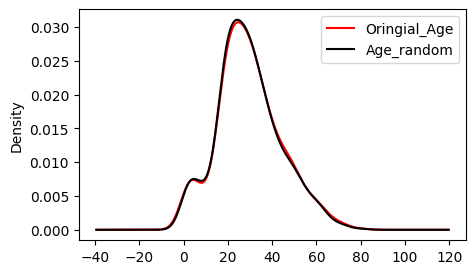

In [48]:
# which one to choose
plt.figure(figsize = (5,3))

df['Age'].plot(kind = 'kde' , color = 'r' , label = 'Oringial_Age')
df['Age_random'].plot(kind = 'kde', color = 'black' , label = 'Age_random')


plt.legend(loc = 0)

plt.show()

In [49]:
print(f"Original Age column : {df['Age'].std()}")
print(f" Age Random Sample  column : {df['Age_random'].std()}")

Original Age column : 14.526497332334044
 Age Random Sample  column : 14.295286948654615
